In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/titanic.csv')

df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:

print("Dataset shape:", df.shape)


df.info()


Dataset shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [4]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:

print("Missing values:")
print(df.isnull().sum())


print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Number of duplicate rows: 107


In [6]:

duplicate_rows = df.duplicated(keep=False)
duplicates = df[duplicate_rows]
duplicates.head(10)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
42,0,3,male,NaN,0,0,7.8958,C,Third,man,True,NaN,Cherbourg,no,True
45,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
46,0,3,male,NaN,1,0,15.5000,Q,Third,man,True,NaN,Queenstown,no,False
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True


In [7]:

print("Passenger survival:")
print(df['alive'].value_counts())

print("\nPassenger class:")
print(df['class'].value_counts())

print("\nGender:")
print(df['sex'].value_counts())

print("\nPort of embarkation:")
print(df['embark_town'].value_counts(dropna=False))


Passenger survival:
alive
no     549
yes    342
Name: count, dtype: int64

Passenger class:
class
Third     491
First     216
Second    184
Name: count, dtype: int64

Gender:
sex
male      577
female    314
Name: count, dtype: int64

Port of embarkation:
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64


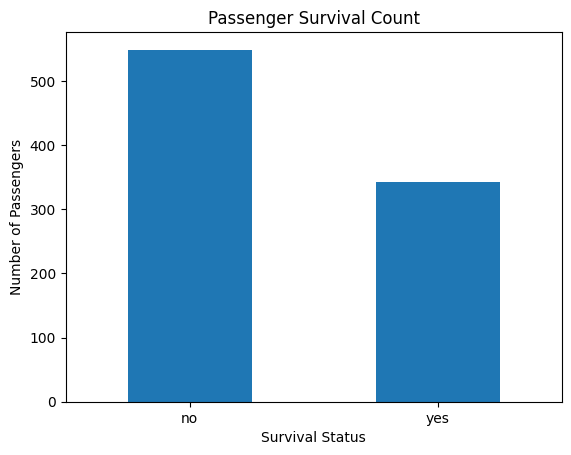

In [8]:

survival_counts = df['alive'].value_counts()


survival_counts.plot(kind='bar')

plt.title('Passenger Survival Count')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.show()


**Observation:** The bar chart shows that 549 passengers did not survive, while 342 passengers survived. This indicates that the majority of passengers in the dataset did not survive the Titanic disaster. The survival rate was approximately 38.4%.


In [10]:

# Compare survival counts by gender
pd.crosstab(df['sex'], df['alive'])


alive,no,yes
sex,,
female,81,233
male,468,109


In [7]:
import pandas as pd

# Ensure df is defined if kernel was restarted
try:
    df
except NameError:
    df = pd.read_csv('/content/titanic.csv')

# Calculate survival rates by gender
gender_survival = pd.crosstab(
    df['sex'],
    df['alive'],
    normalize='index'
) * 100

gender_survival

alive,no,yes
sex,,
female,25.796178,74.203822
male,81.109185,18.890815


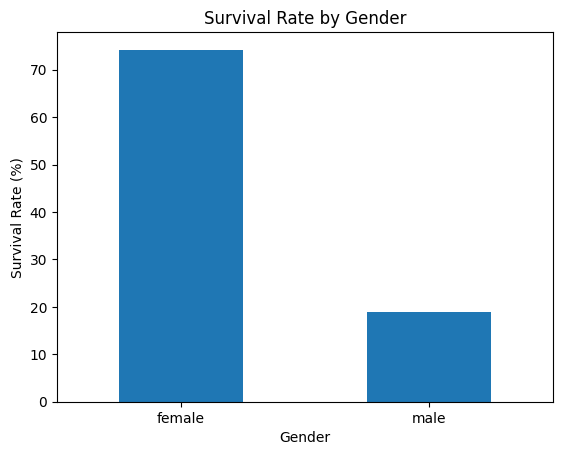

In [8]:

# Plot survival rates by gender
gender_survival['yes'].plot(kind='bar')

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()


**Observation:** Female passengers had a much higher survival rate than male passengers. Approximately 74.2% of female passengers survived, compared with 18.9% of male passengers. This shows a strong association between gender and survival in the Titanic dataset.

In [9]:

# Compare survival counts by passenger class
pd.crosstab(df['class'], df['alive'])


alive,no,yes
class,,
First,80,136
Second,97,87
Third,372,119


In [10]:

# Calculate survival rates by passenger class
class_survival = pd.crosstab(
    df['class'],
    df['alive'],
    normalize='index'
) * 100

class_survival


alive,no,yes
class,,
First,37.037037,62.962963
Second,52.717391,47.282609
Third,75.763747,24.236253


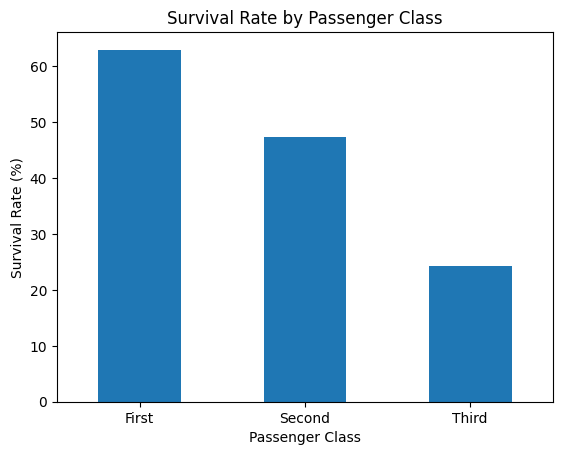

In [11]:

# Plot survival rate by passenger class
class_survival['yes'].plot(kind='bar')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()


**Observation — Survival Rate by Passenger Class**

The analysis shows that first-class passengers had the highest survival rate at approximately 63%, followed by second-class passengers at 47.3%. Third-class passengers had the lowest survival rate at around 24.2%. This indicates a noticeable association between passenger class and survival in the Titanic dataset.

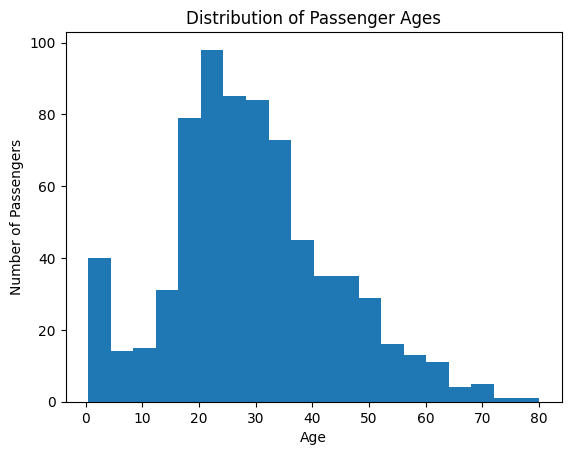

In [12]:

# Explore the distribution of passenger ages
plt.hist(df['age'].dropna(), bins=20)

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()


**Observation — Distribution of Passenger Ages**

The histogram shows that most passengers with recorded ages were between approximately 20 and 35 years. The frequency of passengers generally decreases at older ages, giving the distribution a longer tail toward the right. A noticeable number of young children were also aboard the Titanic.

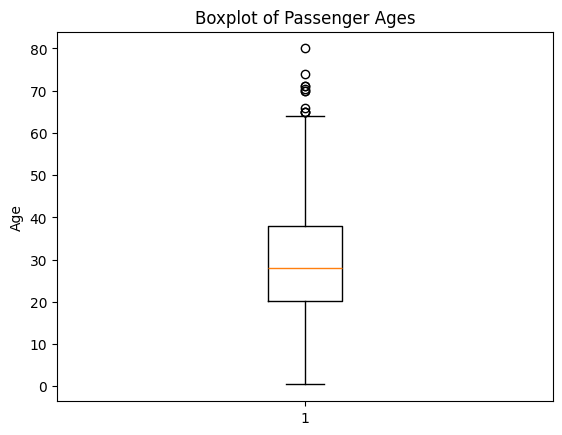

In [13]:

# Examine the distribution of passenger ages using a boxplot
plt.boxplot(df['age'].dropna())

plt.title('Boxplot of Passenger Ages')
plt.ylabel('Age')
plt.show()


**Observation — Boxplot of Passenger Ages**

The boxplot shows a median passenger age of approximately 28 years, with the middle 50% of recorded ages falling between around 20 and 38 years. Several older ages appear beyond the upper whisker and are flagged as potential outliers. These observations should be investigated rather than removed automatically.

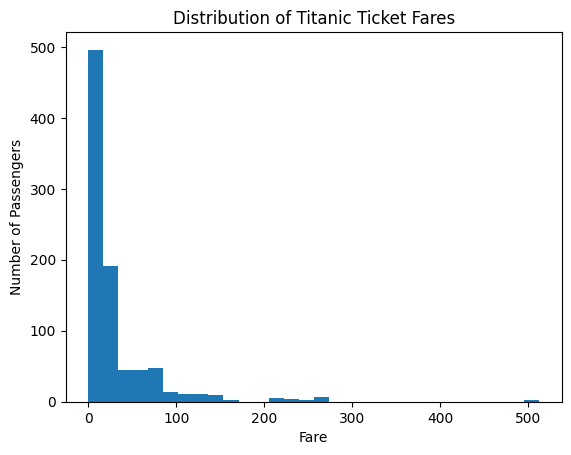

In [14]:

# Examine the distribution of ticket fares
plt.hist(df['fare'], bins=30)

plt.title('Distribution of Titanic Ticket Fares')
plt.xlabel('Fare')
plt.ylabel('Number of Passengers')
plt.show()


**Observation — Distribution of Ticket Fares**

The histogram shows that most passengers paid relatively low ticket fares. The distribution is strongly right-skewed, with a small number of passengers paying substantially higher fares. These high values may represent premium tickets or other fare-related differences and can be investigated further using a boxplot.

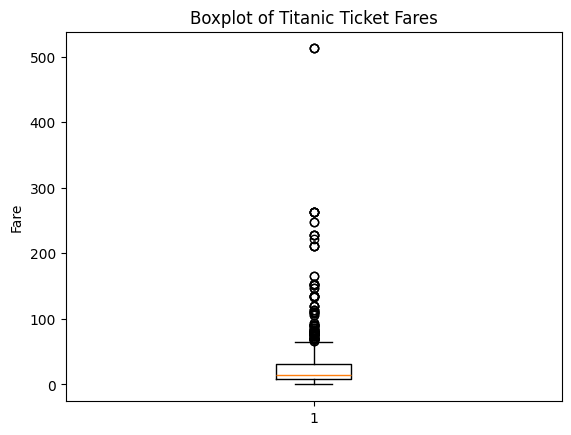

In [15]:

# Check the spread of ticket fares and potential outliers
plt.boxplot(df['fare'])

plt.title('Boxplot of Titanic Ticket Fares')
plt.ylabel('Fare')
plt.show()


**Observation — Boxplot of Titanic Ticket Fares**

The boxplot shows that ticket fares are concentrated toward the lower end of the distribution, with a median of approximately 14.45. Several observations lie above the upper whisker, including a maximum fare of around 512.33. These values are potential outliers and should be investigated rather than removed automatically.

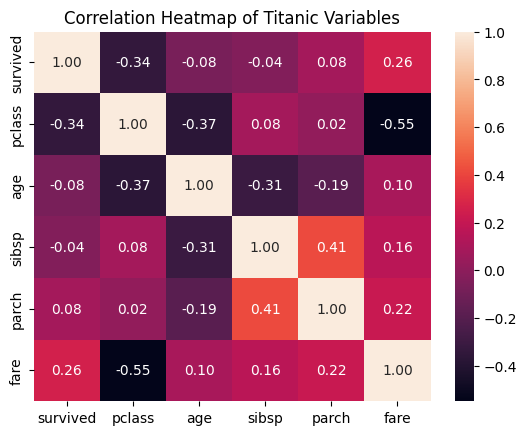

In [16]:

# Select numerical columns for correlation analysis
numeric_data = df.select_dtypes(include='number')

# Calculate correlations
correlation_matrix = numeric_data.corr()

# Display the correlation heatmap
sns.heatmap(correlation_matrix, annot=True, fmt='.2f')
plt.title('Correlation Heatmap of Titanic Variables')
plt.show()


**Observation — Correlation Heatmap**

The heatmap shows a negative correlation between passenger class code and fare (-0.55), indicating that higher class codes are associated with lower fares. Survival has a negative correlation with passenger class (-0.34) and a positive correlation with fare (0.26). The number of siblings/spouses and parents/children aboard has a positive correlation (0.41). These relationships help identify variables worth exploring further, but correlation alone does not establish causation.

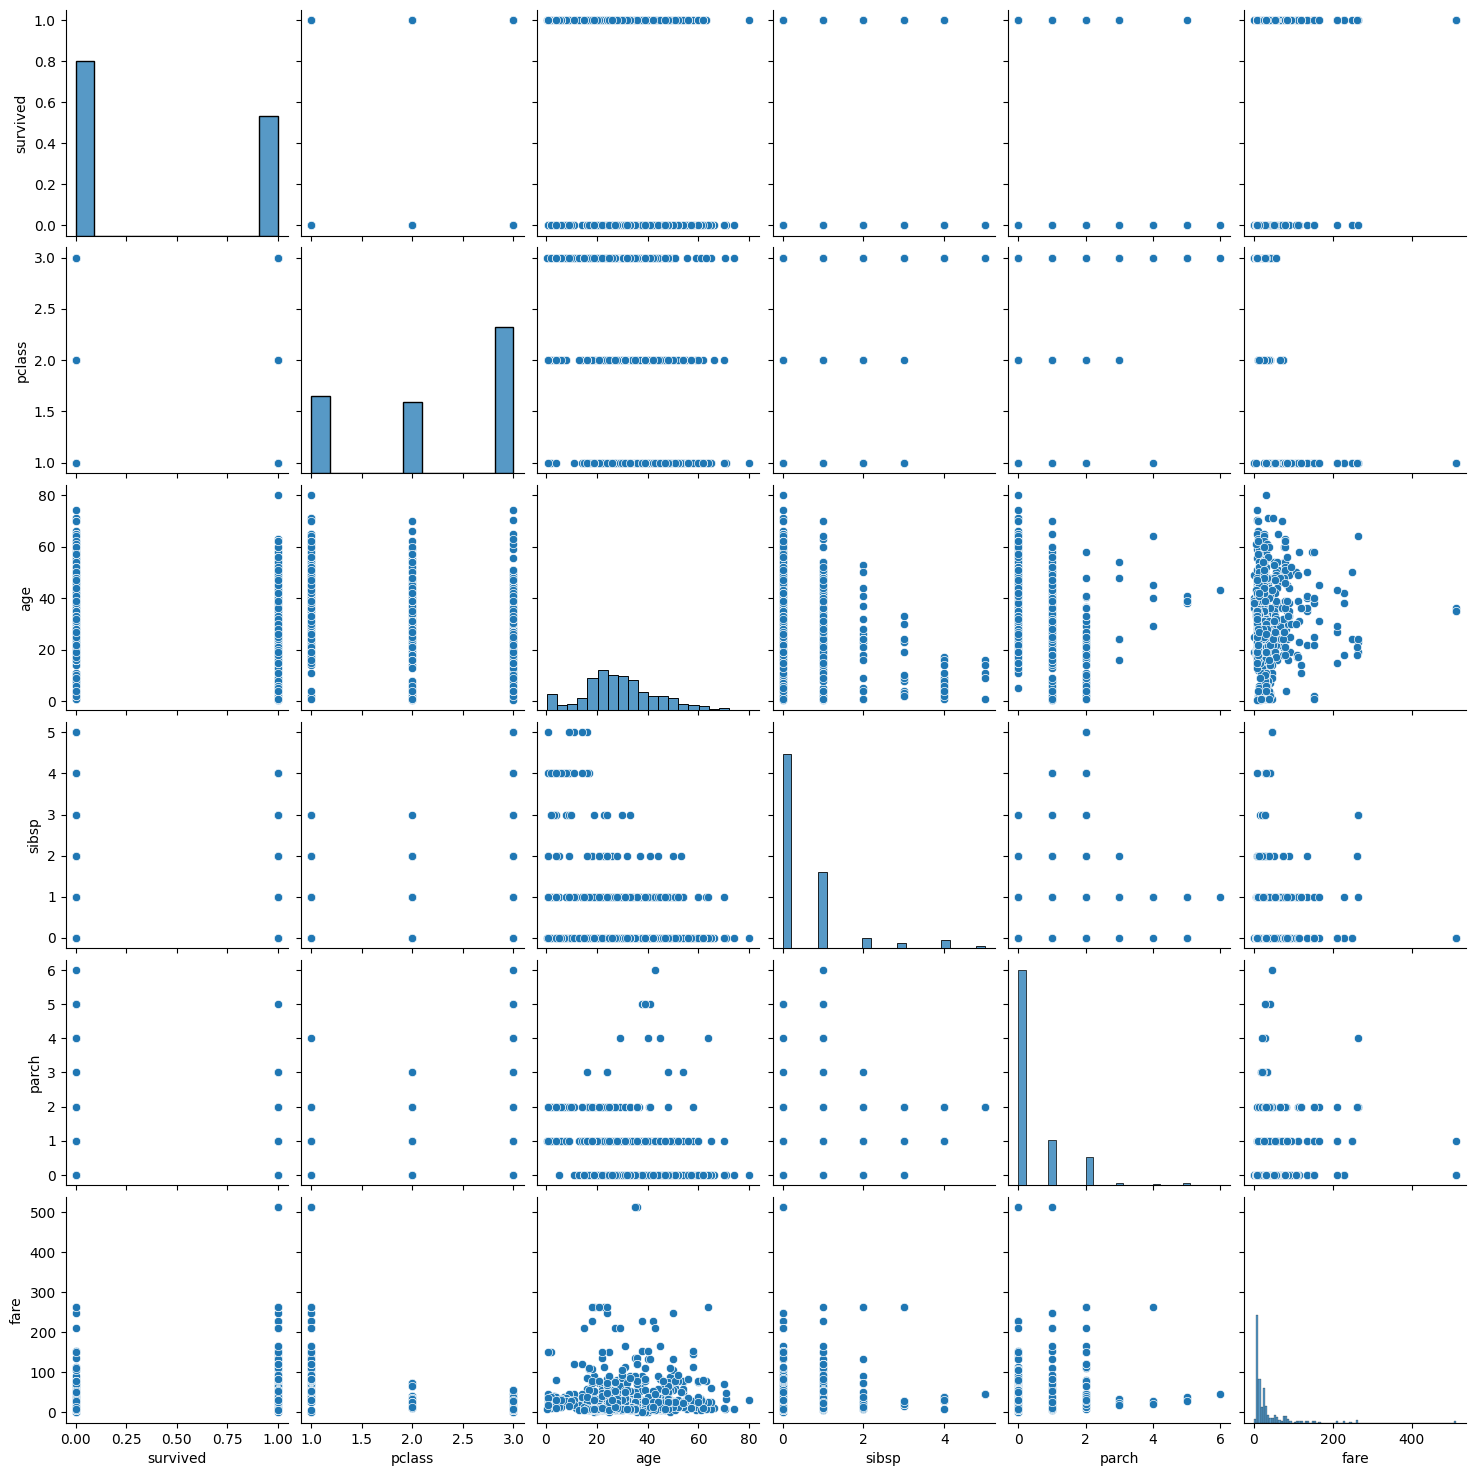

In [17]:


# Examine relationships among numerical variables
sns.pairplot(
    df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']].dropna()
)

plt.show()


**Observation — Pairplot of Numerical Variables**

The pairplot shows that passenger ages were concentrated mainly among young adults, while ticket fares were strongly right-skewed. Passenger class and fare show a negative relationship, consistent with the correlation heatmap. Most passengers had relatively few siblings, spouses, parents, or children aboard. Since survival and passenger class are coded as discrete numerical variables, their scatterplot panels form distinct bands rather than continuous distributions.

In [18]:

# Compare survival rates across age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

age_survival = pd.crosstab(
    df['age_group'],
    df['alive'],
    normalize='index'
) * 100

age_survival


alive,no,yes
age_group,,
Child,42.028986,57.971014
Teenager,57.142857,42.857143
Young Adult,61.731844,38.268156
Adult,60.000000,40.000000
Senior,77.272727,22.727273


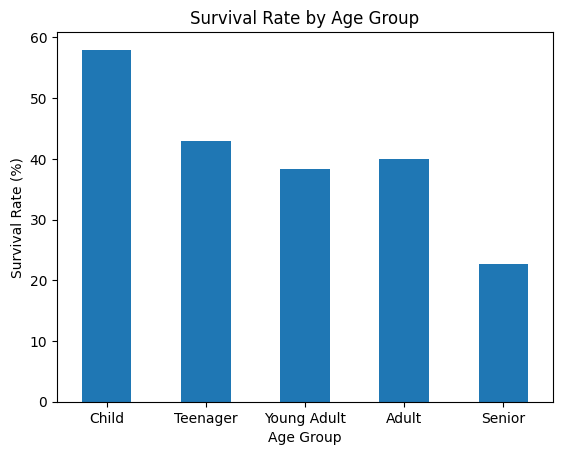

In [19]:

# Plot survival rates across age groups
age_survival['yes'].plot(kind='bar')

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()


**Observation — Survival Rate by Age Group**

The analysis shows that children had the highest survival rate, at approximately 58%, while seniors had the lowest rate, at around 22.7%. Survival rates for teenagers, young adults, and adults ranged from approximately 38% to 43%. This suggests an association between age group and survival among passengers with recorded ages.

In [20]:

# Compare survival rates by gender and passenger class
pd.crosstab(
    [df['class'], df['sex']],
    df['alive'],
    normalize='index'
).mul(100).round(2)


alive             no    yes
class  sex                 
First  female   3.19  96.81
       male    63.11  36.89
Second female   7.89  92.11
       male    84.26  15.74
Third  female  50.00  50.00
       male    86.46  13.54

In [21]:

survival_by_class_gender = pd.crosstab(
    [df['class'], df['sex']],
    df['alive'],
    normalize='index'
).mul(100).round(2)

survival_by_class_gender.columns.name = 'Survival Status (%)'

survival_by_class_gender


Survival Status (%)     no    yes
class  sex                       
First  female         3.19  96.81
       male          63.11  36.89
Second female         7.89  92.11
       male          84.26  15.74
Third  female        50.00  50.00
       male          86.46  13.54

**Observation — Survival by Gender and Passenger Class**

The analysis shows that female passengers had higher survival rates than male passengers within each passenger class. First-class females had the highest survival rate at approximately 96.8%, followed by second-class females at 92.1%. Among male passengers, the survival rate decreased from 36.9% in first class to 13.5% in third class. These findings suggest that survival patterns differed by both gender and passenger class.

# Final Findings and Conclusion

## Key Findings

1. **Overall survival:** Out of 891 passengers, 342 survived and 549 did not survive. The overall survival rate was approximately 38.4%.

2. **Gender and survival:** Female passengers had a survival rate of approximately 74.2%, compared with 18.9% among male passengers.

3. **Passenger class:** First-class passengers had the highest survival rate (63.0%), followed by second-class passengers (47.3%) and third-class passengers (24.2%).

4. **Age and survival:** Children had the highest survival rate among the age groups examined (58.0%), while seniors had the lowest (22.7%). This analysis excludes passengers with missing ages.

5. **Age distribution:** Passenger ages were concentrated mainly among young adults, with a median of approximately 28 years.

6. **Fare distribution:** Ticket fares were strongly right-skewed, with many passengers paying relatively low fares and a small number paying substantially higher fares.

7. **Relationships between variables:** The correlation heatmap showed a negative correlation between passenger class code and fare (-0.55) and a positive correlation between fare and survival (0.26). These relationships require contextual interpretation and do not establish causation.

## Data Quality and Limitations

- Age had 177 missing values, deck had 688, and embarkation information had two missing values.
- The initial duplicate check flagged 107 rows, excluding the first occurrence of each matching group. These records were not automatically removed because identical recorded attributes do not necessarily prove duplicate passengers.
- The analysis is descriptive and identifies associations rather than causal relationships.
- Pairplot results were based on complete observations for the selected numerical variables.

## Conclusion

The exploratory analysis identified differences in survival rates by gender, passenger class, and age group. It also revealed skewness in ticket fares, potential outliers, and missing data that should be considered when interpreting the results. These findings demonstrate how statistical summaries and visualizations can be used to identify patterns and data-quality issues in a dataset.